# Preprosesing data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os
import tensorflow as tf
from sklearn.preprocessing import OrdinalEncoder
import lightgbm as lgb
import os, sys, gc, time, warnings, pickle, psutil, random
from tqdm import tqdm
from math import ceil
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import math
from statsmodels.tsa.seasonal import STL
from scipy import stats
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Import data cần xử lý vào

Chúng ta sẽ làm việc với 3 file data chính là calendar, prices, sales.

Tập prices chứa các cột về giá cả của từng mặt hàng, sales chứa thông tin về doanh số từng ngày từ d_1 -> d_1968 với định dạng là ngang, calendar thì chứa thông tin ngày tháng thôi

In [ ]:
path = "../data"

calendar = pd.read_csv(os.path.join(path, "calendar.csv"))
prices = pd.read_csv(os.path.join(path, "sell_prices.csv"))
sales = pd.read_csv(os.path.join(path, "sales_train_evaluation.csv"))

Hàm prep_calendar:

* Xoá cột không cần thiết.

* Chuyển cột d về số nguyên.

* Mã hóa các tên sự kiện thành số nguyên.

* Ép kiểu các cột số để tiết kiệm bộ nhớ.

In [ ]:
def prep_calendar(df):
    df = df.drop(["weekday", "event_type_1", "event_type_2"], axis=1)
    df = df.assign(d = df.d.str[2:].astype(int))
    to_ordinal = ["event_name_1", "event_name_2"] 
    df[to_ordinal] = df[to_ordinal].fillna("1")
    df[to_ordinal] = OrdinalEncoder(dtype="int").fit_transform(df[to_ordinal]) + 1
    to_int8 = ["wday", "month", "snap_CA", "snap_TX", "snap_WI"] + to_ordinal
    df[to_int8] = df[to_int8].astype("int8")
    
    return df

calendar = prep_calendar(calendar)
calendar.head()

,date,wm_yr_wk,wday,month,year,d,event_name_1,event_name_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,1,1,2011,1,1,1,0,0,0
1,2011-01-30,11101,2,1,2011,2,1,1,0,0,0
2,2011-01-31,11101,3,1,2011,3,1,1,0,0,0
3,2011-02-01,11101,4,2,2011,4,1,1,1,1,0
4,2011-02-02,11101,5,2,2011,5,1,1,1,0,1


### 🧠 Hàm `downcast(df)` – Giảm kích thước DataFrame

Hàm này giúp **tối ưu bộ nhớ** bằng cách ép kiểu dữ liệu các cột sang dạng nhỏ nhất phù hợp, mà vẫn giữ nguyên giá trị.

---

#### ✅ Mục đích:
- Giảm dung lượng bộ nhớ RAM khi làm việc với dữ liệu lớn.
- Tăng hiệu suất xử lý.

---

#### 🔍 Cách hoạt động:

1. **Lặp qua từng cột trong DataFrame**.
2. Nếu là **kiểu số nguyên (`int`)**:
   - Ép kiểu thành `int8`, `int16`, `int32`, hoặc `int64` tùy theo giá trị min/max.
3. Nếu là **kiểu số thực (`float`)**:
   - Ép kiểu thành `float32` nếu phù hợp.
   - Tránh dùng `float16` (vì không tương thích với Parquet).
4. Nếu là **chuỗi (`object`)**:
   - Nếu cột tên là `date` → chuyển thành `datetime`.
   - Các cột khác → chuyển thành `category`. ( phần này thì sẽ cân nhắc, vì cần tính tới mức độ cần thiết và không làm mất đi data quan trọng)


In [5]:
def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)    
    return df

Chạy hàm downcast cho cả 3 bộ dataset

In [ ]:
# Calculate memory usage before running the function
memory_before = {
    'calendar': calendar.memory_usage(deep=True).sum(),
    'sales': sales.memory_usage(deep=True).sum(),
    'prices': prices.memory_usage(deep=True).sum()
}

sales = downcast(sales)
prices = downcast(prices)
calendar = downcast(calendar)

memory_after = {
    'calendar': calendar.memory_usage(deep=True).sum(),
    'sales': sales.memory_usage(deep=True).sum(),
    'prices': prices.memory_usage(deep=True).sum()
}

Plot ra sự so sánh giữa trước và sau khi downcast để chứng minh rằng việc downcast là cần thiết và có ý nghĩa

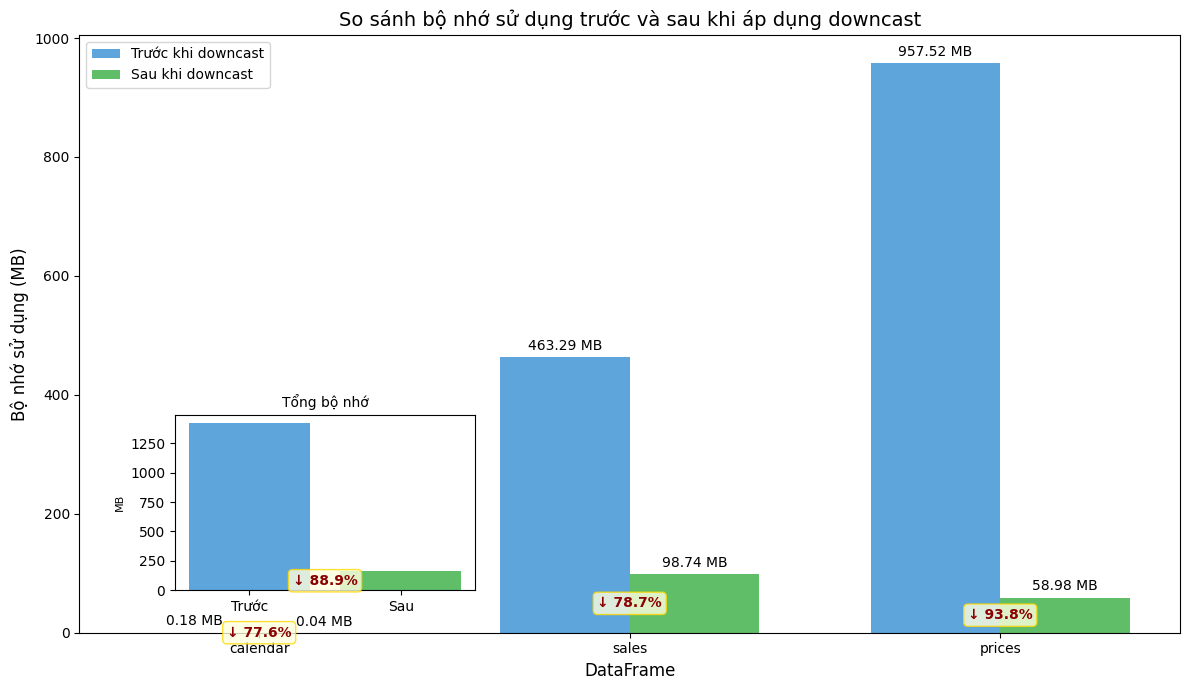


Thông tin chi tiết về bộ nhớ sử dụng:
DataFrame  Trước (MB)      Sau (MB)        Giảm (MB)       Giảm (%)  
----------------------------------------------------------------------
calendar   0.18            0.04            0.14            77.6      
sales      463.29          98.74           364.56          78.7      
prices     957.52          58.98           898.54          93.8      
----------------------------------------------------------------------
TỔNG       1420.99         157.76          1263.23         88.9      


In [ ]:
def plot_memory_comparison(memory_before, memory_after):
    """
    Vẽ biểu đồ so sánh bộ nhớ sử dụng trước và sau khi tối ưu hóa.
    
    Parameters:
    -----------
    memory_before : dict
        Dictionary chứa bộ nhớ sử dụng trước khi tối ưu hóa.
    memory_after : dict
        Dictionary chứa bộ nhớ sử dụng sau khi tối ưu hóa.
    """
    
    # Lấy tên của các DataFrame
    df_names = list(memory_before.keys())
    
    # Tính toán giá trị bộ nhớ ở MB
    before_mb = [memory_before[name] / (1024 * 1024) for name in df_names]
    after_mb = [memory_after[name] / (1024 * 1024) for name in df_names]
    
    # Tính phần trăm giảm bộ nhớ
    reduction_pct = [(memory_before[name] - memory_after[name]) / memory_before[name] * 100 for name in df_names]
    
    # Thiết lập vị trí của các cột
    x = np.arange(len(df_names))
    width = 0.35
    
    # Tạo biểu đồ
    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Vẽ cột
    rects1 = ax.bar(x - width/2, before_mb, width, label='Trước khi downcast', color='#5DA5DA')
    rects2 = ax.bar(x + width/2, after_mb, width, label='Sau khi downcast', color='#60BD68')
    
    # Thêm nhãn, tiêu đề và các thông tin khác
    ax.set_xlabel('DataFrame', fontsize=12)
    ax.set_ylabel('Bộ nhớ sử dụng (MB)', fontsize=12)
    ax.set_title('So sánh bộ nhớ sử dụng trước và sau khi áp dụng downcast', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(df_names)
    ax.legend()
    
    # Thêm giá trị lên mỗi cột
    def add_labels(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.2f} MB',
                         xy=(rect.get_x() + rect.get_width() / 2, height),
                         xytext=(0, 3),  # 3 points vertical offset
                         textcoords="offset points",
                         ha='center', va='bottom')
    
    add_labels(rects1)
    add_labels(rects2)
    
    # Thêm phần trăm giảm bộ nhớ
    for i, pct in enumerate(reduction_pct):
        ax.annotate(f'↓ {pct:.1f}%',
                    xy=(x[i], min(before_mb[i], after_mb[i]) / 2),
                    xytext=(0, 0),
                    textcoords="offset points",
                    ha='center', va='center',
                    color='darkred',
                    fontweight='bold',
                    bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
    plt.tight_layout()
    
    # Thêm biểu đồ tổng hợp
    ax2 = fig.add_axes([0.15, 0.15, 0.25, 0.25])
    total_before = sum(before_mb)
    total_after = sum(after_mb)
    total_reduction = (total_before - total_after) / total_before * 100
    
    ax2.bar(['Trước', 'Sau'], [total_before, total_after], color=['#5DA5DA', '#60BD68'])
    ax2.set_title('Tổng bộ nhớ', fontsize=10)
    ax2.set_ylabel('MB', fontsize=8)
    ax2.annotate(f'↓ {total_reduction:.1f}%', 
                xy=(0.5, min(total_before, total_after) / 2),
                xytext=(0, 0),
                textcoords="offset points",
                ha='center', va='center',
                color='darkred',
                fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
    plt.show()
    
    # In thông tin chi tiết
    print("\nThông tin chi tiết về bộ nhớ sử dụng:")
    print(f"{'DataFrame':<10} {'Trước (MB)':<15} {'Sau (MB)':<15} {'Giảm (MB)':<15} {'Giảm (%)':<10}")
    print("-" * 70)
    
    for i, name in enumerate(df_names):
        reduced = memory_before[name] - memory_after[name]
        reduced_mb = reduced / (1024 * 1024)
        print(f"{name:<10} {before_mb[i]:<15.2f} {after_mb[i]:<15.2f} {reduced_mb:<15.2f} {reduction_pct[i]:<10.1f}")
    
    print("-" * 70)
    total_reduced_mb = (sum(memory_before.values()) - sum(memory_after.values())) / (1024 * 1024)
    print(f"{'TỔNG':<10} {total_before:<15.2f} {total_after:<15.2f} {total_reduced_mb:<15.2f} {total_reduction:<10.1f}")

# Sử dụng hàm
plot_memory_comparison(memory_before, memory_after)

### 💾 Vì sao nên lưu file dưới dạng `.parquet` thay vì `.csv`?

- **Dung lượng nhỏ hơn** nhờ hỗ trợ nén và lưu trữ theo cột.
- **Tốc độ đọc/ghi nhanh hơn** nhiều so với `.csv`.
- **Giữ nguyên kiểu dữ liệu** (dtype), không cần xử lý lại sau khi load.
- **Linh hoạt khi xử lý**, chỉ cần đọc các cột cần thiết.


In [ ]:
calendar.to_parquet('done_cal.parquet')
sales.to_parquet('done_sales.parquet')
prices.to_parquet('done_prices.parquet')

In [ ]:
calendar

,date,wm_yr_wk,wday,month,year,d,event_name_1,event_name_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,1,1,2011,1,1,1,0,0,0
1,2011-01-30,11101,2,1,2011,2,1,1,0,0,0
2,2011-01-31,11101,3,1,2011,3,1,1,0,0,0
3,2011-02-01,11101,4,2,2011,4,1,1,1,1,0
4,2011-02-02,11101,5,2,2011,5,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
1964,2016-06-15,11620,5,6,2016,1965,1,1,0,1,1
1965,2016-06-16,11620,6,6,2016,1966,1,1,0,0,0
1966,2016-06-17,11620,7,6,2016,1967,1,1,0,0,0
1967,2016-06-18,11621,1,6,2016,1968,1,1,0,0,0


Sau mỗi lần dùng và tạo ra df mà không cần sử dụng nữa thì ta dùng del và gc.collect() để xóa bộ nhớ

In [ ]:
import gc
del calendar, prices, sales
gc.collect()

5631

# Xử lí dữ liệu disasater để thêm một cột dữ liệu cho df gốc.

Quy tắc là thêm một cột disaster_severity_flag nhằm biểu thị mức độ nghiệm trọng của thiên tai ảnh hưởng tới doanh thu của hàng hóa, nếu doanh thu ít mà trong ngày đó xảy ra thiên tai thì chứng tỏ thiên tai có ảnh hưởng nghiêm trọng tới doanh thu, doanh thu càng thấp thì flag có giá trị càng cao và ngược lại, ở đây nhóm em đề xuất sử dụng thang đo là 15( có thể thử nghiệm thêm nhiều thang đo tùy thôi, test nhiều thang để biết thang nào có hiệu suất cao nhất)

In [14]:
disater = pd.read_csv('../data/us_disasters_m5.csv')

def prep_disater(disater):
    done_dis = disater[['state', 'incident_type', 'incident_begin_date', 'incident_end_date']].copy()
    
    # Chuyển đổi kiểu datetime
    done_dis['incident_begin_date'] = pd.to_datetime(done_dis['incident_begin_date'], errors='coerce')
    done_dis['incident_end_date'] = pd.to_datetime(done_dis['incident_end_date'], errors='coerce')
    
    # Thay thế giá trị thiếu trong incident_end_date
    done_dis['incident_end_date'] = done_dis['incident_end_date'].fillna(
        done_dis['incident_begin_date'] + pd.Timedelta(days=1)
    )
    
    done_dis['incident_begin_date'] = done_dis['incident_begin_date'].dt.tz_localize(None)
    done_dis['incident_end_date'] = done_dis['incident_end_date'].dt.tz_localize(None)
    
    return done_dis

done_dis = prep_disater(disater)

print(done_dis['incident_type'].unique())
print(done_dis['state'].unique())

from sklearn.preprocessing import LabelEncoder

# B1: Gắn tên bang từ state_id để khớp done_dis
label_encoder = LabelEncoder()
done_dis['state'] = label_encoder.fit_transform(done_dis['state'])+1

done_dis.to_parquet('../data/done_dis.parquet')

['Fire' 'Snow' 'Tsunami' 'Severe Storm(s)' 'Other' 'Earthquake' 'Flood']
['TX' 'WI' 'CA']


In [15]:
import gc
del done_dis, disater
gc.collect()

0

In [2]:
calendar = pd.read_parquet('done_cal.parquet')

prices = pd.read_parquet('done_prices.parquet')

sales = pd.read_parquet('done_sales.parquet')

done_dis = pd.read_parquet('../data/done_dis.parquet')

# Merge data giữa sales, calendar và prices


1. **Hàm `demand_features(df)`:**
   - Tạo các features dựa trên lịch sử nhu cầu
   - Tính toán giá trị lag (trễ) cho mỗi sản phẩm
   - Tính trung bình động (rolling mean) cho các giá trị lag

2. **Hàm `prep_data(df, drop_d=1000)`:**
   - Loại bỏ dữ liệu cũ trước ngày `drop_d`
   - Chuyển dữ liệu từ dạng rộng (wide) sang dạng dài (long)
   - Tạo features từ dữ liệu nhu cầu (demand)
   - Kết hợp với dữ liệu lịch (calendar) và giá (prices)
   - Mã hóa các biến phân loại (categorical) thành dạng số

In [3]:
from sklearn.model_selection import train_test_split

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features(df):
    """ Derive features from sales data and remove rows with missing values """
    
    for lag in LAGS:
        df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
        for w in WINDOWS:
            df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")
        
    return df

def prep_data(df, drop_d=1000):
    """ Prepare model data sets """
    
    # Kick out old dates
    df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

    # Reshape to long
    df = df.assign(id=df.id.str.replace("_evaluation", ""))
    df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
    df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
    df = df.assign(d=df.d.str[2:].astype("int64"),
                   demand=df.demand.astype("float32"))
    
    # Add demand features
    df = demand_features(df)
    
    # Remove rows with NAs
    df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]
 
    # Join calendar & prices
    df = df.merge(calendar, how="left", on="d")
    df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
    df = df.drop(["wm_yr_wk"], axis=1)
    
    # Ordinal encoding of remaining categorical fields
    for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
        df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1
    
    return df

df = prep_data(sales, 1000 - 28)
print(f'{round(df.memory_usage(deep=True).sum()/1024**2,2)} MB')

4097.29 MB


### Code này để thêm features flag disater như đã phân tích ở trên

In [7]:
# B3: Khởi tạo cột disaster_type (ban đầu là None)
df['disaster_type'] = None

# B4: Gắn loại thảm họa cho các ngày bị ảnh hưởng
for _, row in done_dis.iterrows():
    mask = (
        (df['state_id'] == row['state']) &
        (df['date'] >= row['incident_begin_date']) &
        (df['date'] <= row['incident_end_date'])
    )
    df.loc[mask, 'disaster_type'] = row['incident_type']

# B5: Tính tổng doanh thu theo loại thảm họa
revenue_by_disaster = df[df['disaster_type'].notna()].groupby('disaster_type')['demand'].sum()

# B6: Chuẩn hóa giá trị doanh thu để gán severity flag
# doanh thu càng thấp => mức độ ảnh hưởng càng nặng
rank = revenue_by_disaster.rank(ascending=True, method='min')  # nhỏ nhất = 1
max_rank = rank.max()
severity_map = (rank / max_rank * 15).astype(int)  # chia thành 1–15

# B7: Gán cột flag theo loại thảm họa
df['disaster_severity_flag'] = df['disaster_type'].map(severity_map)
df['disaster_severity_flag'] = df['disaster_severity_flag'].fillna(0).astype(int)  # nếu không bị thiên tai thì là 0


In [ ]:
import gc
del calendar, prices, sales # sau khi dùng xong và không cần dùng lại thì xóa đi cho đỡ chiếm bộ nhớnhớ
gc.collect()
df['state_id'].unique()
done_dis['state'].unique()

0

In [8]:
print(df.columns)
print(df['disaster_severity_flag'].unique())

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag'],
      dtype='object')
[ 0 15  3  7 11]


In [ ]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from sklearn.preprocessing import StandardScaler, MinMaxScaler
# import os
# import tensorflow as tf
# from sklearn.preprocessing import OrdinalEncoder
# import lightgbm as lgb
# import os, sys, gc, time, warnings, pickle, psutil, random
# from tqdm import tqdm
# from math import ceil
# from sklearn.preprocessing import LabelEncoder
# from sklearn.model_selection import train_test_split
# import math
# from statsmodels.tsa.seasonal import STL
# from scipy import stats
# print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
# print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag', 'flag_ufc'],
      dtype='object')
[ 0 15  3  7 11]
['HOBBIES_1_001_CA_1' 'HOBBIES_1_002_CA_1' 'HOBBIES_1_003_CA_1' ...
 'FOODS_3_825_WI_3' 'FOODS_3_826_WI_3' 'FOODS_3_827_WI_3']
28691090


## **Xử lý outlier:** 
* Xác định danh sách ID duy nhất trong dữ liệu
* Duyệt qua từng ID:
  * In tiến độ sau mỗi 1000 ID
  * Lọc dữ liệu theo ID
  * Tạo dataframe chuỗi thời gian với date và demand
  * Tính Exponential Moving Average (EMA)
  * Phát hiện outlier bằng một trong hai cách:
     * Nếu đủ dữ liệu (≥ 2*period): Dùng STL để phân tách xu hướng và mùa vụ, sau đó tìm outlier trong phần dư
     * Nếu không đủ dữ liệu: Áp dụng z-score trực tiếp lên giá trị demand
  * Thay thế các giá trị outlier bằng giá trị EMA tương ứng

In [ ]:
del grid_df
gc.collect()

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'wday',
       'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA', 'snap_TX',
       'snap_WI', 'sell_price', 'disaster_type', 'disaster_severity_flag',
       'flag_ufc'],
      dtype='object')
['HOBBIES_1_001_CA_1' 'HOBBIES_1_002_CA_1' 'HOBBIES_1_003_CA_1'
 'HOBBIES_1_004_CA_1' 'HOBBIES_1_005_CA_1']
    timestamps  demand     d  EMA
238 2014-07-18     3.0  1267    3
267 2014-08-16     4.0  1296    3
283 2014-09-01     4.0  1312    3
364 2014-11-21     3.0  1393    3
387 2014-12-14     4.0  1416    4
    timestamps  demand     d  EMA
163 2014-05-04     2.0  1192    2
183 2014-05-24     2.0  1212    2
212 2014-06-22     3.0  1241    3
224 2014-07-04     2.0  1253    2
252 2014-08-01     2.0  1281    2
    timestamps  demand     d  EMA
77  2014-02-07     3.0  1106

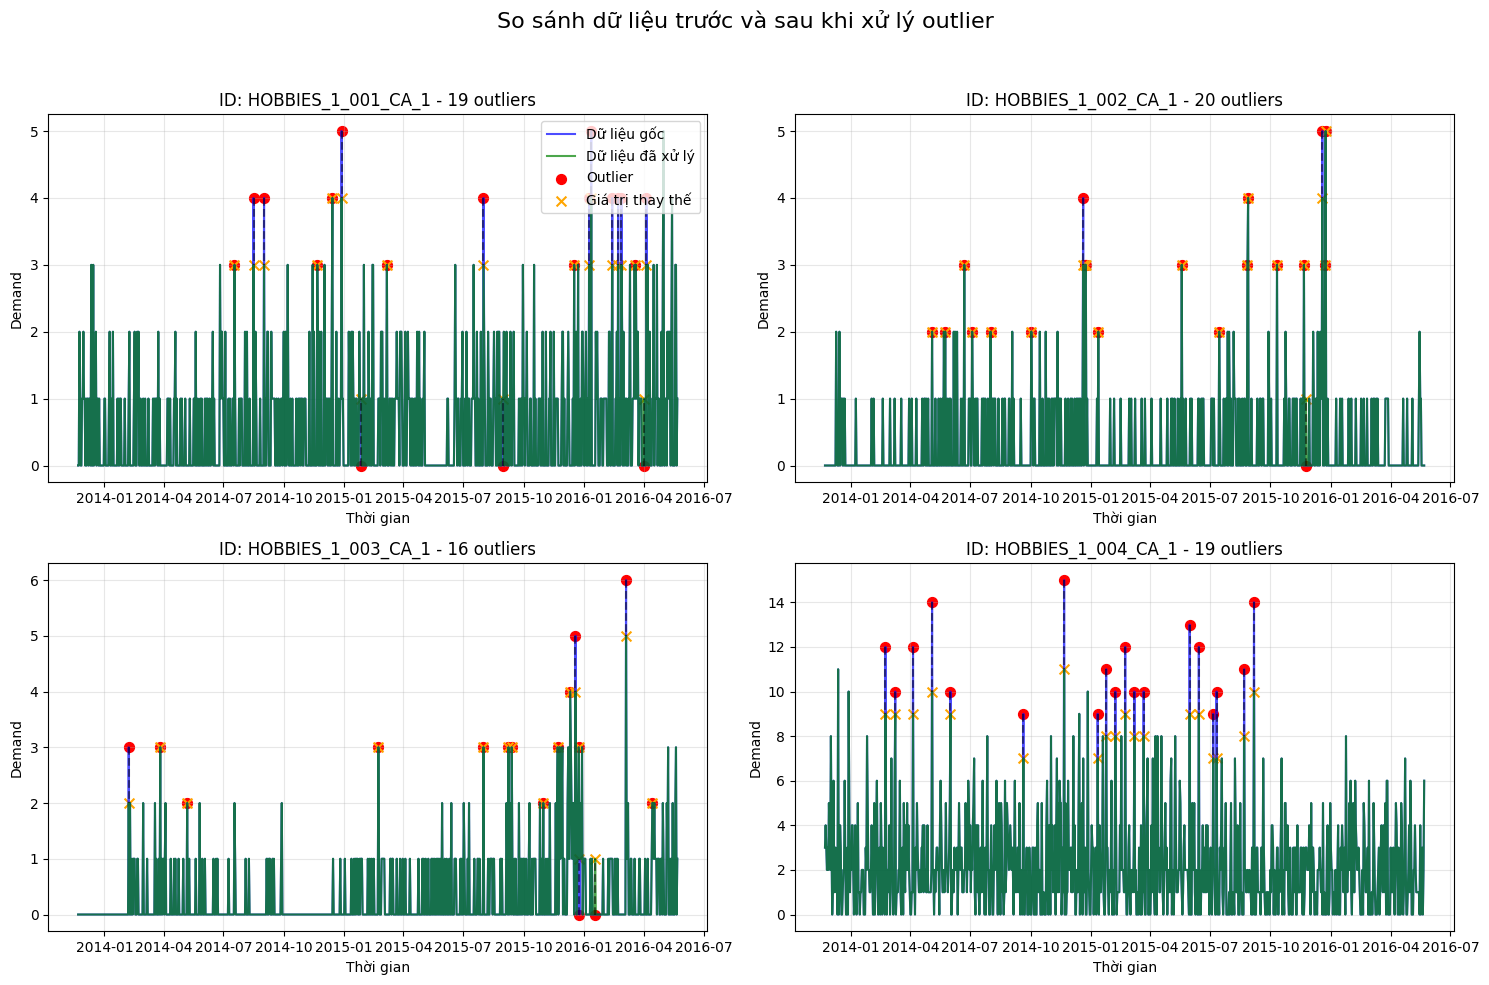

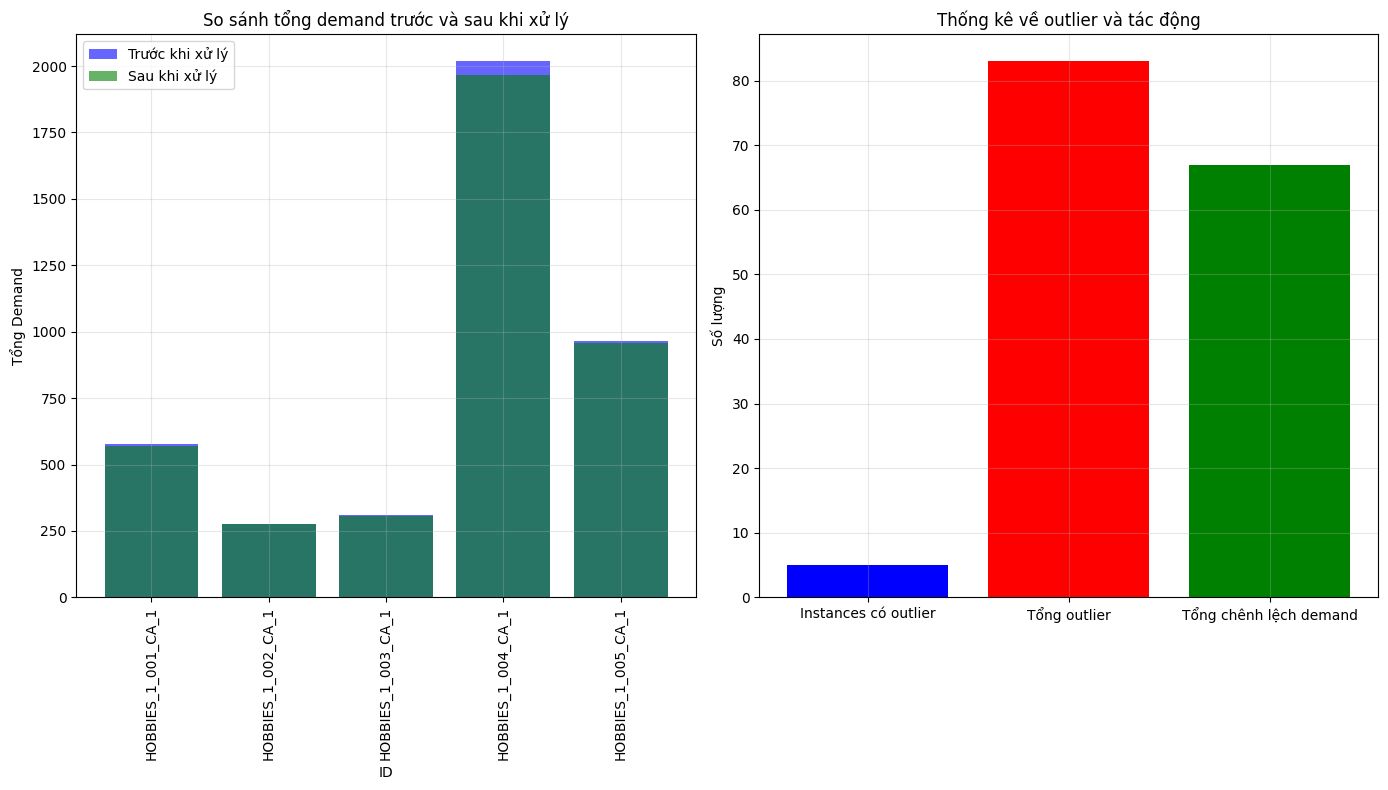


Tổng kết:
Đã xử lý 5 instance
Có 5 instance chứa outlier
Tổng số outlier phát hiện được: 83
Tổng mức chênh lệch demand: 67.0

Bảng so sánh chi tiết:
                   ID  Demand gốc  Demand xử lý  Chênh lệch  \
0  HOBBIES_1_001_CA_1       576.0         569.0        -7.0   
1  HOBBIES_1_002_CA_1       276.0         275.0        -1.0   
2  HOBBIES_1_003_CA_1       309.0         308.0        -1.0   
3  HOBBIES_1_004_CA_1      2018.0        1967.0       -51.0   
4  HOBBIES_1_005_CA_1       965.0         958.0        -7.0   

   Phần trăm thay đổi  
0               -1.22  
1               -0.36  
2               -0.32  
3               -2.53  
4               -0.73  


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from statsmodels.tsa.seasonal import STL
from scipy import stats
import matplotlib.dates as mdates

# Đọc dữ liệu
grid_df = pd.read_parquet('../data/train_val.parquet')
grid_df = grid_df.drop(['date'], axis=1)
grid_df = grid_df.dropna(subset=['demand'])
print(grid_df.columns)
duplicate_id_list = grid_df[grid_df.duplicated('id', keep=False)]['id'].unique()
duplicate_id_list = duplicate_id_list[:5]
print(duplicate_id_list)

cal = pd.read_parquet('done_cal.parquet')
# print(cal)

# Để lưu dữ liệu gốc cho việc so sánh sau này
original_grid_df = grid_df.copy()

# Tạo figure cho biểu đồ tổng hợp
plt.figure(figsize=(15, 10))
plt.suptitle('So sánh dữ liệu trước và sau khi xử lý outlier', fontsize=16)

# Số lượng instance được xử lý
processed_instances = 0
# Số lượng outlier được phát hiện
total_outliers = 0

cnt = 0
for instance in duplicate_id_list:
  cnt += 1
  if cnt % 100 == 0:
    break
  filtered_df = grid_df[grid_df.id == instance]

  sales_ts = pd.DataFrame({
     'timestamps': filtered_df['d'].values,
     'demand': filtered_df['demand'].values
  })
  sales_ts['d'] = sales_ts['timestamps'] # keep sales_ts['d'] as integer

  # Merge với calendar_df theo cột 'd'
  sales_ts = sales_ts.merge(cal[['d', 'date']], on='d', how='left')

  sales_ts['timestamps'] = sales_ts['date']
  sales_ts = sales_ts.drop(columns=['date'])

  sales_ts['EMA'] = sales_ts['demand'].ewm(span=2, adjust=False).mean()
  sales_ts['EMA'] = sales_ts['EMA'].apply(math.ceil)

  from statsmodels.tsa.seasonal import STL
  from scipy import stats
  import numpy as np

  # Phân tích chuỗi theo mùa vụ
  stl = STL(sales_ts['demand'], period=30)  # nếu data theo ngày, 7 là 1 tuần
  res = stl.fit()

  residual = res.resid

  # Áp dụng z-score để tìm outlier trong residual
  z = np.abs(stats.zscore(residual))
  threshold = 2.8  # ngưỡng z-score
  outliers = sales_ts[z > threshold]
  print(outliers.head())
  
  # Cập nhật số lượng outliers
  total_outliers += len(outliers)
  
  # Nếu có outlier, vẽ biểu đồ so sánh
  if len(outliers) > 0:
    processed_instances += 1
    
    # Tạo một bản sao của sales_ts để lưu giá trị EMA
    processed_sales_ts = sales_ts.copy()
    for idx, row in outliers.iterrows():
      processed_sales_ts.loc[idx, 'demand'] = row['EMA']

    # Chỉ vẽ biểu đồ cho 4 instance đầu tiên có outlier
    if processed_instances <= 4:
      plt.subplot(2, 2, processed_instances)
      
      # Vẽ dữ liệu gốc
      plt.plot(sales_ts['timestamps'], sales_ts['demand'], 'b-', label='Dữ liệu gốc', alpha=0.7)
      
      # Vẽ dữ liệu đã xử lý
      plt.plot(processed_sales_ts['timestamps'], processed_sales_ts['demand'], 'g-', label='Dữ liệu đã xử lý', alpha=0.7)
      
      # Đánh dấu outliers
      plt.scatter(outliers['timestamps'], outliers['demand'], color='red', s=50, label='Outlier')
      plt.scatter(outliers['timestamps'], outliers['EMA'], color='orange', s=50, marker='x', label='Giá trị thay thế')
      
      # Kết nối outlier trước và sau khi xử lý
      for idx, row in outliers.iterrows():
        plt.plot([row['timestamps'], row['timestamps']], [row['demand'], row['EMA']], 'k--', alpha=0.5)
      
      plt.title(f'ID: {instance} - {len(outliers)} outliers')
      plt.xlabel('Thời gian')
      plt.ylabel('Demand')
      plt.grid(True, alpha=0.3)
      
      # Nếu đây là biểu đồ đầu tiên, hiển thị legend
      if processed_instances == 1:
        plt.legend(loc='upper right')

  # Cập nhật dữ liệu grid_df
  for idx, row in outliers.iterrows():
    grid_df.loc[(grid_df.id == instance) & (grid_df['d'] == row['d']), 'demand'] = row['EMA']

# Điều chỉnh layout
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Điều chỉnh khoảng cách để có chỗ cho tiêu đề lớn
plt.savefig('outlier_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Tạo biểu đồ thống kê về outliers
plt.figure(figsize=(14, 8))

# Vẽ biểu đồ số lượng outlier theo instance
if processed_instances > 0:
  # Tính toán phân phối lượng outlier trước và sau khi xử lý
  all_ids = []
  original_values = []
  processed_values = []
  
  for instance in duplicate_id_list[:min(cnt, len(duplicate_id_list))]:
    # Lấy dữ liệu gốc và đã xử lý
    orig_df = original_grid_df[original_grid_df.id == instance]
    proc_df = grid_df[grid_df.id == instance]
    
    # Tính tổng demand
    orig_sum = orig_df['demand'].sum()
    proc_sum = proc_df['demand'].sum()
    
    if orig_sum != proc_sum:  # Chỉ xem xét các instance đã thay đổi
      all_ids.append(instance)
      original_values.append(orig_sum)
      processed_values.append(proc_sum)
  
  # Tạo biểu đồ so sánh tổng demand
  plt.subplot(1, 2, 1)
  if len(all_ids) > 0:
    plt.bar(range(len(all_ids)), original_values, alpha=0.6, color='blue', label='Trước khi xử lý')
    plt.bar(range(len(all_ids)), processed_values, alpha=0.6, color='green', label='Sau khi xử lý')
    plt.xticks(range(len(all_ids)), all_ids, rotation=90)
    plt.xlabel('ID')
    plt.ylabel('Tổng Demand')
    plt.title('So sánh tổng demand trước và sau khi xử lý')
    plt.legend()
    plt.grid(True, alpha=0.3)
  
  # Tạo biểu đồ thống kê chung
  plt.subplot(1, 2, 2)
  
  # Tính toán tổng sự khác biệt
  total_diff = sum(abs(np.array(original_values) - np.array(processed_values))) if len(original_values) > 0 else 0
  
  stats_data = [
    processed_instances,  # Số instance có outlier
    total_outliers,       # Tổng số outlier
    total_diff            # Tổng sự khác biệt về demand
  ]
  
  plt.bar(['Instances có outlier', 'Tổng outlier', 'Tổng chênh lệch demand'], stats_data, color=['blue', 'red', 'green'])
  plt.ylabel('Số lượng')
  plt.title('Thống kê về outlier và tác động')
  plt.grid(True, alpha=0.3)
  
  plt.tight_layout()
  plt.savefig('outlier_statistics.png', dpi=300, bbox_inches='tight')
  plt.show()
  
  # In thông tin tổng hợp
  print(f"\nTổng kết:")
  print(f"Đã xử lý {cnt} instance")
  print(f"Có {processed_instances} instance chứa outlier")
  print(f"Tổng số outlier phát hiện được: {total_outliers}")
  print(f"Tổng mức chênh lệch demand: {total_diff}")
  
  # Tạo một bảng so sánh chi tiết
  if len(all_ids) > 0:
    comparison_df = pd.DataFrame({
      'ID': all_ids,
      'Demand gốc': original_values,
      'Demand xử lý': processed_values,
      'Chênh lệch': np.array(processed_values) - np.array(original_values),
      'Phần trăm thay đổi': ((np.array(processed_values) - np.array(original_values)) / np.array(original_values) * 100).round(2)
    })
    print("\nBảng so sánh chi tiết:")
    print(comparison_df)
else:
  plt.text(0.5, 0.5, 'Không tìm thấy outlier nào!', 
         horizontalalignment='center', verticalalignment='center', fontsize=20)
  plt.axis('off')
  plt.tight_layout()
  plt.savefig('outlier_statistics.png', dpi=300, bbox_inches='tight')
  plt.show()

In [28]:
len(grid_df.columns)

26

## Xử lý null values

In [ ]:
# Đọc dữ liệu từ file Parquet
grid_df = pd.read_parquet('../data/train_val.parquet')

# Loại bỏ các dòng có giá trị 'demand' bị thiếu
grid_df = grid_df.dropna(subset=['demand'])

# Tạo điều kiện lọc cho sản phẩm cụ thể
m = grid_df.id=='HOBBIES_1_288_CA_1'

# Trích xuất chuỗi thời gian của lượng bán ra ('demand') cho sản phẩm đó
sales_ts = grid_df.loc[m,'demand'].values

# Hàm tìm khoảng thời gian không bán được hàng (gaps)
def gap_finder(ts):
    # Đánh dấu các ngày không có doanh số (demand == 0) là 1, còn lại là 0
    ts = (~(ts > 0)).astype(int)

    # Lặp qua từng ngày để xác định độ dài của mỗi khoảng trống
    for i, val in enumerate(ts):
        if val == 0: 
            continue  # nếu ngày có doanh số, bỏ qua
        else: 
            ts[i] += ts[i-1]  # cộng dồn số ngày liên tiếp không bán được hàng
            ts[i-1] = -1       # đánh dấu ngày trước là đã xử lý
    return ts  # Trả về mảng với các độ dài khoảng trống

# Hàm đếm số lần xuất hiện của mỗi độ dài khoảng trống
def gap_counter(ts):
    # Trả về dictionary: độ dài gap -> số lần xuất hiện
    counts = np.unique(ts, return_counts=True)
    return dict(zip(counts[0], counts[1]))

# Áp dụng hai hàm trên cho sản phẩm cụ thể để lấy thông tin khoảng trống
m = grid_df.id=='HOBBIES_1_288_CA_1'
sales_gaps = gap_counter(gap_finder(grid_df.loc[m,'demand'].values))

# Giả lập một chuỗi thời gian tổng hợp dựa trên khoảng trống có thật
# Giả định xác suất bán được hàng mỗi ngày là như nhau
# Hàm này sẽ tạo chuỗi nhị phân: 1 nếu bán được, 0 nếu không

def synth_sales(gaps_dict, min_gap=1000):
    # Lấy số ngày bán được hàng (tức là các gap có độ dài = 0)
    sum_sale_days = gaps_dict.get(0, 0)  # nếu không có key 0 thì trả về 0
    
    # Tổng số ngày trong chuỗi dữ liệu (bao gồm cả ngày bán và không bán)
    sum_days = sum(gaps_dict.values())
    
    # Tổng số ngày trong các khoảng trống dài hơn `min_gap`
    sum_gap_length = sum([k for k in [*sales_gaps.keys()] if k > min_gap])
    
    # Tính xác suất bán hàng: loại bỏ những gap quá dài khỏi mẫu tính
    p = sum_sale_days / (sum_days - sum_gap_length)
    
    # Tạo chuỗi nhị phân với xác suất p, độ dài = tổng số ngày
    return np.random.binomial(1, p, sum(gaps_dict.values()))

# Áp dụng các hàm để đếm khoảng trống trong chuỗi dữ liệu tổng hợp
synth_sales_gaps = gap_counter(gap_finder(synth_sales(sales_gaps)))

# In ra thống kê khoảng trống trong dữ liệu tổng hợp
synth_sales_gaps

{-1: 505, 0: 180, 1: 103, 2: 56, 3: 30, 4: 17, 5: 11, 6: 4, 7: 4, 8: 2, 9: 1}

### Phát hiện Hết Hàng Dựa trên Dữ liệu Bán Hàng

---

Đoạn code này thực hiện việc phát hiện các ngày **hết hàng tiềm năng** (out-of-stock) cho một sản phẩm bằng cách mô phỏng và so sánh với dữ liệu thực tế. Toàn bộ quy trình gồm 4 bước chính:

---

### 📌 1. Mô phỏng chuỗi bán hàng (Simulation)
- Giả lập chuỗi bán hàng nhị phân (1: bán được, 0: không bán) dựa trên xác suất thực tế.
- Chạy mô phỏng 1,000 lần để thu thập thống kê về **độ dài các khoảng trống không bán được hàng (gaps)**.
- Tính tần suất xuất hiện của từng độ dài gap qua `gap_length_prob`.

---

### 📌 2. Xác định ngưỡng gap bất thường (`min_gap_length`)
- Những gap hiếm xuất hiện (dưới 5% trong mô phỏng) được coi là bất thường.
- Tìm **độ dài nhỏ nhất** trong số các gap bất thường và gán cho `min_gap_length`.
- Giả định: các gap dài bất thường có thể do sản phẩm thật sự hết hàng, không phải ngẫu nhiên.

---

### 📌 3. Tái mô phỏng để hiệu chỉnh ngưỡng
- Các gap dài bất thường được loại bỏ khỏi việc tính xác suất bán hàng trong mô phỏng tiếp theo.
- Lặp lại mô phỏng cho đến khi `min_gap_length` ổn định (không thay đổi giữa các vòng lặp).

---

### 📌 4. Tạo feature `out_of_stock`
- Áp dụng hàm phát hiện gap cho dữ liệu thực tế.
- Nếu một gap dài hơn `min_gap_length` → đánh dấu là `True` (tức sản phẩm bị hết hàng).
- Trả về chuỗi boolean `gf`, biểu thị các ngày sản phẩm có thể đã hết hàng.

---

🔍 **Ý nghĩa ứng dụng:** Giúp tách biệt các khoảng trống do yếu tố thị trường (không có nhu cầu) với các khoảng trống do nguyên nhân logistics (hết hàng) – hỗ trợ cho việc phân tích tồn kho, dự báo nhu cầu và tối ưu chuỗi cung ứng.


In [3]:
# As you can see we dont have results > 20. 
# To make sure this is a consistent result lets run simulation 1,000 times:
# >>>> n equal 1,000 might be an overshot for some ids.

n=1000

sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps))) for i in range(n)])
gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()
gap_length_prob

# The shortest gap that has been seen in less than 5% of simulated series:
min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)
min_gap_length

# Now we exclude the gaps longer than min_gap_length from 'probability of sale' calculation, 
# because we assume them to be non-random.
# Run the simulation recursively until the min_gap_length does not decrease:

n=1000
new_min_gap_length = 0

while new_min_gap_length != min_gap_length:
    
    if new_min_gap_length!=0: min_gap_length=new_min_gap_length

    sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps, min_gap_length))) for i in range(n)])
    gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()

    # Lets find the shortes gap that has been seen in les than 5% of simulated series:
    new_min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)

min_gap_length

# Finally we need to make a feature 'out_of_stock' for the product:
m = grid_df.id=='HOBBIES_1_288_CA_1'
idx = grid_df.loc[m,'demand'].index

gf = pd.Series(gap_finder(grid_df.loc[m,'demand'].values), index = idx)
gf = gf.replace(-1,np.nan).fillna(method='backfill') 
gf = gf > min_gap_length
gf

280         False
30770       False
61260       False
91750       False
122240      False
            ...  
27685200    False
27715690    False
27746180    False
27776670    False
27807160    False
Length: 913, dtype: bool

In [4]:
grid_df['out_of_stock'] = 0
n = 1000
prods = list(grid_df.id.unique())[:5]
gap_length_list = []

for prod_id in tqdm(prods):
    m = grid_df.id == prod_id
    idx = grid_df.loc[m, 'demand'].index

    sales_gaps = gap_counter(gap_finder(grid_df.loc[m, 'demand'].values))
    sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps))) for _ in range(n)])
    gap_length_prob = (sym_df.sum(axis=0) / n).sort_index()

    # Nếu không có giá trị nào < 0.05 thì bỏ qua sản phẩm này
    if (gap_length_prob < 0.05).sum() == 0:
        continue

    min_gap_length = min(gap_length_prob[gap_length_prob < 0.05].index)
    new_min_gap_length = 0

    while new_min_gap_length < min_gap_length:
        if new_min_gap_length != 0:
            min_gap_length = new_min_gap_length

        sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps, min_gap_length))) for _ in range(n)])
        gap_length_prob = (sym_df.sum(axis=0) / n).sort_index()

        if (gap_length_prob < 0.05).sum() == 0:
            break
        new_min_gap_length = min(gap_length_prob[gap_length_prob < 0.05].index)

    gf = pd.Series(gap_finder(grid_df.loc[m, 'demand'].values), index=idx)
    gf = gf.replace(-1, np.nan).fillna(method='backfill')
    gf = gf > min_gap_length
    grid_df.loc[m, 'out_of_stock'] = gf * 1
    gap_length_list.append(min_gap_length)

100%|██████████| 5/5 [00:08<00:00,  1.63s/it]


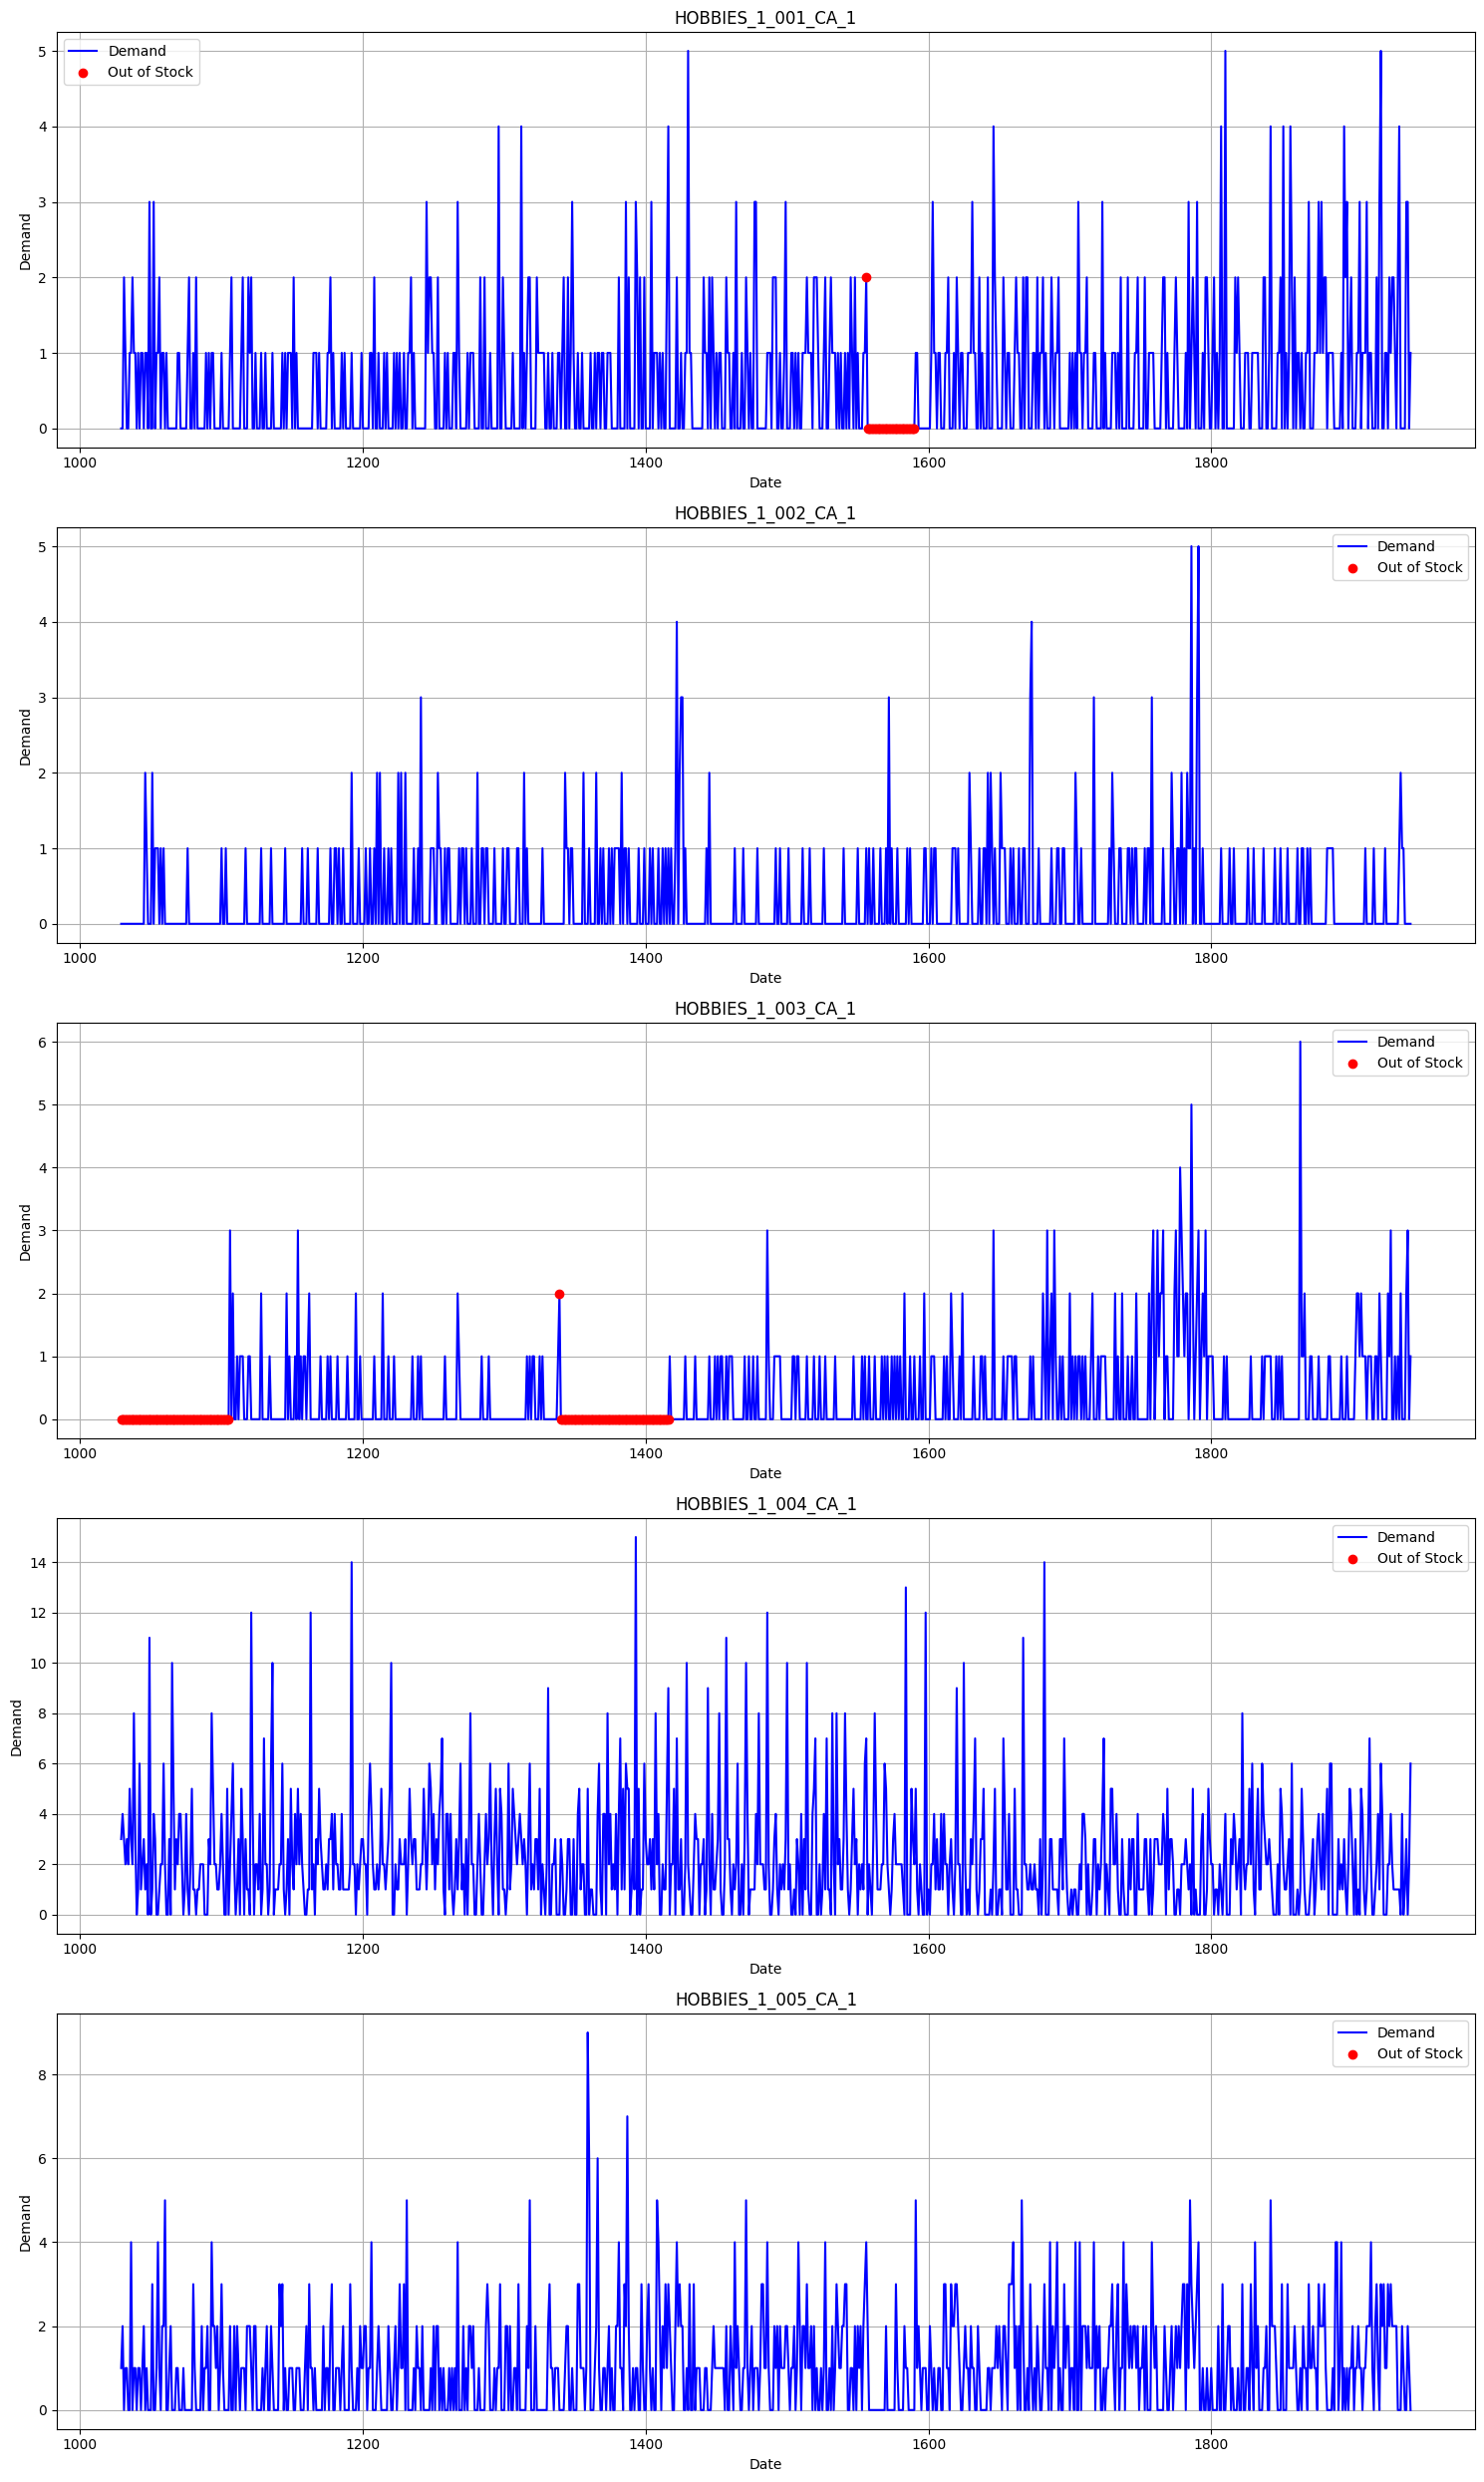

In [5]:
plt.figure(figsize=(15, 25))

for i, prod_id in enumerate(prods):
    plt.subplot(5, 1, i + 1)
    m = grid_df.id == prod_id
    prod_df = grid_df.loc[m]

    plt.plot(prod_df['d'], prod_df['demand'], label='Demand', color='blue')

    out_days = prod_df[prod_df['out_of_stock'] == 1]
    plt.scatter(out_days['d'], out_days['demand'], color='red', label='Out of Stock', zorder=5)

    plt.title(f'{prod_id}')
    plt.xlabel('Date')
    plt.ylabel('Demand')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

Ở đây ta thấy việc phân biệt giữa hết hàng không có hàng để bán với hàng đang ế sẽ tạo thêm một feature mới đáng để xem xét nhằm tăng hiệu suất cho mô hình

In [ ]:
df.to_parquet('../data/train_val.parquet')
print(f'{round(df.memory_usage(deep=True).sum()/1024**2,2)} MB')
del df
gc.collect()

4999.74 MB


0

# Kết thúc